<a href="https://colab.research.google.com/github/steffanylars/nus-web-mining-business-insights/blob/main/Step3_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 3: Feature Engineering

**BT4222 Final Project, Group 13, JDSearch**

Step 3 turns each (session, candidate) pair into 26 numbers a ranker can use. The main idea comes from Step 1: the log keeps clicks for about a week, carts for about three months and orders for about a year, so *what* a user did and *how long ago* are the same variable.

The features describes **two horizons**, short-term intent (recent clicks and carts) and long-term preference (orders of any age), instead of weighting actions by an assumed intent order.

* **Part A** rebuilds the step. It needs the inputs listed below.
* **Part B** reads the measured outputs of the corrected run (`artifacts/corrected`) and re-checks them.
  It needs no raw data, so it always runs and its outputs are saved in this copy of the notebook.

| Section | What it does | Writes |
|---|---|---|
| A.1 | Load Step 2 tables | - |
| A.2 | Product lookups: category, brand, name tokens | - |
| A.3 | Popularity priors from training histories only | - |
| A.4 | Per-session history profile (counts, recency) | - |
| A.5 | Horizon sets, decayed affinity, seen items, past queries | - |
| A.6 | One feature row per candidate | - |
| A.7 | Assemble, check finiteness, save | `features.parquet`, `feature_summary.json` |
| A.8 | Quick look at mean features by label | - |
| B.1 | Feature dictionary vs the saved summary | - |
| B.2 | Do features separate the labels? | - |

**Inputs.** `candidates`, `history`, `sessions`, `meta_subset` from Step 2.

**Outputs.** `features.parquet` (one row per candidate, 26 float features and IDs, label and split) and `feature_summary.json`.

## No leakage by construction

* A session's history contains only events **before** its query.
* Labels do not enter any feature.
* Popularity priors are counted on **training** sessions' histories only.
* Query tokens are matched against product text that exists independently of the label.
* The split comes from Step 2 and is never changed here.

## Feature dictionary (26 features)

| Group | Feature | Meaning |
|---|---|---|
| Query vs product | `query_len` | number of query tokens |
| | `slate_size` | number of candidates in the slate |
| | `has_meta` | the candidate has a metadata row |
| | `ov_name`, `ov_cat`, `ov_brand` | query tokens shared with the product name, level-3 category name, brand name |
| | `jacc_name` | Jaccard similarity between query tokens and product-name tokens |
| Popularity (train only) | `pop_wid`, `pop_cate3`, `pop_brand` | log(1 + count) of the item, its level-3 category and its brand in training histories |
| Horizon match | `short_cat_hit`, `short_brand_hit` | candidate category / brand appears in the user's **short** horizon (clicks of the last 7 days, carts of the last 90 days) |
| | `long_cat_hit`, `long_brand_hit` | candidate category / brand appears among the user's **orders** (any age) |
| Recency-weighted affinity | `aff_cat_decay`, `aff_brand_decay` | sum over history events in the same category / brand of exp(-age_days / 30) |
| Re-engagement | `seen_before` | the exact product is in the user's preceding history |
| | `q_hist_overlap` | query tokens shared with the user's earlier non-empty queries |
| User activity | `h_len`, `h_n_click`, `h_n_cart`, `h_n_ord` | history length and counts by action type |
| | `h_n_recent7`, `h_n_distinct_c3` | events in the last 7 days, distinct level-3 categories |
| | `h_min_elapsed` | age of the user's **most recent** event (not candidate-specific) |
| | `h_queryless` | share of history events without a query (`-1`) |

## Environment setup


In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib

import os, sys, subprocess, shutil, tarfile, csv, time
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "main"                         # final submission branch
MOUNT_DRIVE = True                      # Colab only: keep raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
    # Install the pinned requirements except torch (keep Colab's preinstalled torch/GPU build).
    reqs = [l.strip() for l in (PROJECT_ROOT / "requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith("#") and not l.lower().startswith("torch")]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *reqs], check=False)
    if MOUNT_DRIVE:
        from google.colab import drive as gdrive
        gdrive.mount("/content/drive")
        drive_path = Path(DRIVE_DIR)
        user_txt = drive_path / "user_behavior_data.txt"
        tgz = drive_path / "JDsearch.tar.gz"
        if not user_txt.exists() and tgz.exists():
            # Extract the raw files once from the Drive tarball into local Colab storage.
            if not Path("/content/JDsearch").exists():
                with tarfile.open(tgz) as t:
                    t.extractall("/content")
            hits = {p.name: p for p in Path("/content").rglob("*.txt")}
            if "user_behavior_data.txt" in hits:
                os.environ["JD_USER_TXT"] = str(hits["user_behavior_data.txt"])
            if "product_meta_data.txt" in hits:
                os.environ["JD_PRODUCT_TXT"] = str(hits["product_meta_data.txt"])
        elif user_txt.exists():
            os.environ["JD_USER_TXT"] = str(user_txt)
            os.environ["JD_PRODUCT_TXT"] = str(drive_path / "product_meta_data.txt")
        os.environ["JD_RUN_DIR"] = str(drive_path / "runs" / "corrected")
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Steps 3 to 7 run without the raw files: seed the run dir from the committed intermediary tables.
RUN_DIR = Path(os.environ.get("JD_RUN_DIR", PROJECT_ROOT / "artifacts" / "corrected"))
(RUN_DIR / "model").mkdir(parents=True, exist_ok=True)
INTERMEDIATE = PROJECT_ROOT / "data" / "intermediate"
for _t in ["candidates", "history", "sessions", "features", "meta_subset"]:
    _dst = RUN_DIR / "model" / (_t + ".parquet")
    _src = INTERMEDIATE / (_t + ".parquet")
    if not _dst.exists() and _src.exists():
        shutil.copy(_src, _dst); print("seeded", _t, "from data/intermediate")

RAW_AVAILABLE = bool(os.environ.get("JD_USER_TXT")) and Path(os.environ.get("JD_USER_TXT", "x")).exists()


def _short(p):
    if p is None:
        return "<unset>"
    s = str(p)
    if s.startswith("<"):
        return s
    parts = Path(s).parts
    return str(Path(*parts[-2:])) if len(parts) >= 2 else str(p)


print("in Colab    :", IN_COLAB)
print("project root:", _short(PROJECT_ROOT))
print("run dir     :", _short(os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>")))
print("raw files   :", "available" if RAW_AVAILABLE else "absent (Steps 3-7 use data/intermediate)")

in Colab    : False
project root: bt4212_finalProj/Final Project
run dir     : local_run/outputs
raw files   : absent (Steps 3-7 use data/intermediate)


## 1. Imports and shared helpers

`tok` splits the anonymised term-id strings on the correct delimiter (`\x18`; the draft split on the
wrong character, which made every category overlap zero). `short_mask` marks the short-horizon events
(clicks of at most 7 days, carts of at most 90 days).

In [2]:
import json, time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from config import OUT, RES, prepare, save_json
from data_utils import tok, short_mask

%matplotlib inline
prepare()

# Only these product columns feed the features (Steps 3/5/7 never read the rest).
META_COLS = ["wid", "cate_id_3", "brand_id", "name", "cate_name_3", "brand_name"]
CAND_CHUNK = 300000  # candidate rows per block; bounds the transient row buffer

def intern_tokens(series):
    """Tokenise each distinct string once and share the resulting set.

    Category and brand names repeat across millions of products (a few thousand
    distinct values), so one set per distinct string, referenced by every wid that
    carries it, gives identical lookups at a fraction of the memory.
    """
    cache = {}
    out = {}
    for w, v in series.items():
        s = cache.get(v)
        if s is None:
            s = tok(v); cache[v] = s
        out[w] = s
    return out


### 1.1 What each part does. (the `RUN_STEP` switch)

Part A rebuilds this step and Part B reads the measured outputs, so the switch below decides whether Part A runs.

* Part A runs only if its **inputs exist**, and it will not overwrite the committed evidence in
  `artifacts/corrected` unless you explicitly allow it (`ALLOW_OVERWRITE`). In Colab the clone is
  disposable, so overwriting is allowed by default; locally, point `JD_RUN_DIR` at a new folder.
* If Part A is skipped, nothing fails: **Part B always runs** and shows the saved results.

In [3]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = all((OUT / f"{n}.parquet").exists() for n in ["candidates", "history", "sessions", "meta_subset"])
# Part A regenerates features from raw product text (name/cate_name_3/brand_name); the committed
# slim meta_subset only carries wid/cate_id_3/brand_id, so Part A needs the raw files or a full meta.
import pyarrow.parquet as _pq
HAS_FULL_META = HAS_INPUTS and ("name" in _pq.read_schema(OUT / "meta_subset.parquet").names)
RUN_STEP = HAS_INPUTS and HAS_FULL_META and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", RES)
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    why = ("required inputs not found: candidates, history, sessions, meta_subset parquet files (run Step 2 first)" if not HAS_INPUTS else
           "outputs would overwrite artifacts/corrected; set JD_RUN_DIR to a new folder or ALLOW_OVERWRITE = True")
    print("Part A is skipped here (" + why + ").")
    print("Part B below shows the measured outputs saved in", RES)

inputs found    : True
outputs go to   : /Users/steff/Documents/GitHub/bt4212_finalProj/local_run/outputs
RUN_STEP        : True


# Part A: Build the features

### A.1 Load the Step 2 tables

In [4]:
if RUN_STEP:
    t0=time.time()
    cand = pd.read_parquet(OUT/"candidates.parquet")
    hist = pd.read_parquet(OUT/"history.parquet")
    sess = pd.read_parquet(OUT/"sessions.parquet")
    meta = pd.read_parquet(OUT/"meta_subset.parquet", columns=META_COLS)
    print(f"loaded: cand {len(cand):,}, hist {len(hist):,}, sess {len(sess):,}, meta {len(meta):,} ({time.time()-t0:.0f}s)")


loaded: cand 1,781,978, hist 3,091,153, sess 20,000, meta 2,246,755 (1s)


### A.2 Product lookups

Dictionaries from product id to level-3 category, brand, and the token sets of the product name,
category name and brand name. They make the per-candidate loop in A.6 a series of fast lookups.

In [5]:
if RUN_STEP:
    meta = meta.set_index("wid")
    # ---- maps wid -> category / brand (every referenced item needs these) ----
    cate3 = meta["cate_id_3"].to_dict()
    brand = meta["brand_id"].to_dict()
    # ---- name/category/brand tokens for candidate items only (content features are candidate-side) ----
    cand_wids = set(cand["cand_wid"].unique())
    mc = meta[meta.index.isin(cand_wids)]
    name_tok = {w: tok(n) for w,n in mc["name"].items()}
    cname3 = intern_tokens(mc["cate_name_3"]) if "cate_name_3" in meta else {}
    bname  = intern_tokens(mc["brand_name"])  if "brand_name" in meta else {}
    del meta, mc; gc.collect()

    train_sids = set(sess.loc[sess.split=="train","session_id"])


### A.3 Popularity priors (training histories only)

How often each item, category and brand appears in the histories of **training** sessions. Validation
and test sessions never contribute to these counts, so there is no data leakage.

In [6]:
if RUN_STEP:
    # ---- POPULARITY PRIORS from TRAIN histories only (no leakage) ----
    hist_tr = hist[hist.session_id.isin(train_sids)]
    wid_pop = hist_tr["wid"].value_counts().to_dict()
    hist_tr_c3 = hist_tr["wid"].map(cate3)
    cate3_pop = hist_tr_c3.value_counts().to_dict()
    hist_tr_b = hist_tr["wid"].map(brand)
    brand_pop = hist_tr_b.value_counts().to_dict()
    del hist_tr, hist_tr_c3, hist_tr_b; gc.collect()
    print(f"priors built ({time.time()-t0:.0f}s)")


priors built (29s)


### A.4 Per-session history profile

Attach category and brand to every history event, flag its type and recency, and flag the **short
horizon** (`intent`). Then aggregate per session: history length, counts by action type, events in the
last 7 days, distinct categories, the age of the most recent event and the share of query-less events.

In [7]:
if RUN_STEP:
    # ---- Per-session history profiles (temporal-aware) ----
    # keep only the columns the profiles read; elapsed_days stays float64 (feeds exp/min exactly)
    hist = hist[["session_id","wid","type","qry","elapsed_days"]].copy()
    hist["c3"] = hist["wid"].map(cate3)
    hist["b"]  = hist["wid"].map(brand)
    hist["is_click"] = (hist["type"]=="CLICK")
    hist["is_cart"]  = (hist["type"]=="CART")
    hist["is_ord"]   = (hist["type"]=="ORD")
    hist["recent7"]  = (hist["elapsed_days"]<=7)
    hist["intent"] = short_mask(hist)

    # per-session aggregates
    g = hist.groupby("session_id")
    sess_feat = pd.DataFrame({
        "h_len": g.size(),
        "h_n_click": g["is_click"].sum(),
        "h_n_cart":  g["is_cart"].sum(),
        "h_n_ord":   g["is_ord"].sum(),
        "h_n_recent7": g["recent7"].sum(),
        "h_n_distinct_c3": g["c3"].nunique(),
        "h_min_elapsed": g["elapsed_days"].min(),
        "h_queryless": g.apply(lambda d: (d["qry"]=="-1").mean(), include_groups=False),
    }).reset_index()


### A.5 Horizon sets, decayed affinity, seen items and past queries

For every session:

* `short_*` sets: categories and brands of the short horizon (recent intent);
* `long_*` sets: categories and brands of the user's orders of any age (lasting preference);
* `seen_wid`: the exact items in the history;
* `aff_c3`, `aff_b`: category and brand affinity with exponential decay, tau = 30 days;
* `sess_qtok`: tokens of the user's earlier non-empty queries.

In [8]:
if RUN_STEP:
    # per-session horizon category/brand sets + recency-weighted affinity dicts
    # short-term intent categories (recent clicks+carts, <=7d emphasises clicks)
    short_c3 = g.apply(lambda d: set(d.loc[d.intent,"c3"].dropna()), include_groups=False).to_dict()
    short_b  = g.apply(lambda d: set(d.loc[d.intent,"b"].dropna()), include_groups=False).to_dict()
    # long-term preference categories/brands from ORDERS (any age)
    long_c3  = g.apply(lambda d: set(d.loc[d.is_ord,"c3"].dropna()), include_groups=False).to_dict()
    long_b   = g.apply(lambda d: set(d.loc[d.is_ord,"b"].dropna()), include_groups=False).to_dict()
    # All exact item IDs from preceding history
    seen_wid = g["wid"].apply(set).to_dict()
    # recency-decayed category affinity (tau=30d) and brand affinity
    aff_c3 = {}; aff_b = {}
    for sid, d in g:
        wv = np.exp(-d["elapsed_days"].values/30.0)
        c3v = d["c3"].values; bv = d["b"].values
        ac={}; ab={}
        for c,w in zip(c3v,wv):
            if pd.notna(c): ac[c]=ac.get(c,0)+w
        for b,w in zip(bv,wv):
            if pd.notna(b): ab[b]=ab.get(b,0)+w
        aff_c3[sid]=ac; aff_b[sid]=ab
    # All preceding history-query tokens per session
    sess_qtok = g.apply(lambda d: set().union(*[tok(q) for q in d["qry"] if q!="-1"]) if (d["qry"]!="-1").any() else set(), include_groups=False).to_dict()
    del hist, g; gc.collect()
    # the candidate loop below only looks up candidate items, so shrink the id/popularity
    # maps to candidate wids and free the full-catalogue versions (value-identical lookups)
    cate3 = {w: cate3[w] for w in cand_wids if w in cate3}
    brand = {w: brand[w] for w in cand_wids if w in brand}
    wid_pop = {w: wid_pop[w] for w in cand_wids if w in wid_pop}
    gc.collect()
    print(f"session profiles built ({time.time()-t0:.0f}s)")


session profiles built (63s)


### A.6 One feature row per candidate

The loop visits every (session, candidate) pair, computes the query-versus-product overlaps, looks up
the popularity priors, checks the horizon hits and the decayed affinity, and records whether the item
was seen before. This is the slowest cell of the step (about 1.8 million rows for the 20,000-user sample).

In [9]:
if RUN_STEP:
    # ---- build feature rows per candidate, in chunks ----
    cand = cand.merge(sess[["session_id","split","slate_size"]], on="session_id", how="left")
    cw = cand["cand_wid"].values; qs = cand["query"].values; sids = cand["session_id"].values
    lab_values = cand["label"].values; split_values = cand["split"].values
    slate_values = cand["slate_size"].values
    query_tokens = {q: tok(q) for q in cand["query"].unique()}
    del cand; gc.collect()
    cols = ["session_id","cand_wid","label","split",
            "query_len","slate_size","has_meta",
            "ov_name","ov_cat","ov_brand","jacc_name",
            "pop_wid","pop_cate3","pop_brand",
            "short_cat_hit","short_brand_hit","long_cat_hit","long_brand_hit",
            "aff_cat_decay","aff_brand_decay","seen_before","q_hist_overlap"]
    n_cand = len(cw); blocks = []
    for start in range(0, n_cand, CAND_CHUNK):
        stop = min(start + CAND_CHUNK, n_cand)
        rows = []
        for i in range(start, stop):
            w = cw[i]; sid = sids[i]
            qt = query_tokens[qs[i]]
            c3 = cate3.get(w); b = brand.get(w)
            has_meta = 1 if w in name_tok else 0
            # content relevance
            nt = name_tok.get(w,set()); ct = cname3.get(w,set()); bt = bname.get(w,set())
            ov_name = len(qt & nt); ov_cat = len(qt & ct); ov_brand = len(qt & bt)
            jacc_name = ov_name/max(len(qt|nt),1)
            # popularity priors (log)
            pop_w = np.log1p(wid_pop.get(w,0))
            pop_c3 = np.log1p(cate3_pop.get(c3,0))
            pop_b = np.log1p(brand_pop.get(b,0))
            # short/long affinity
            sc = short_c3.get(sid,set()); sb = short_b.get(sid,set())
            lc = long_c3.get(sid,set()); lb = long_b.get(sid,set())
            short_cat_hit = 1 if (c3 is not None and c3 in sc) else 0
            short_brand_hit = 1 if (b is not None and b in sb) else 0
            long_cat_hit  = 1 if (c3 is not None and c3 in lc) else 0
            long_brand_hit = 1 if (b is not None and b in lb) else 0
            aff_cat = aff_c3.get(sid,{}).get(c3,0.0)
            aff_brand = aff_b.get(sid,{}).get(b,0.0)
            # exact re-engagement
            seen = 1 if w in seen_wid.get(sid,set()) else 0
            # query overlap with user's past queries
            q_hist_overlap = len(qt & sess_qtok.get(sid,set()))
            rows.append((sid, w, lab_values[i], split_values[i],
                         len(qt), slate_values[i], has_meta,
                         ov_name, ov_cat, ov_brand, jacc_name,
                         pop_w, pop_c3, pop_b,
                         short_cat_hit, short_brand_hit, long_cat_hit, long_brand_hit,
                         aff_cat, aff_brand, seen, q_hist_overlap))
        blocks.append(pd.DataFrame(rows, columns=cols))
        del rows
        print(f"  feat {stop:,}/{n_cand:,} ({time.time()-t0:.0f}s)", flush=True)


  feat 300,000/1,781,978 (69s)


  feat 600,000/1,781,978 (73s)


  feat 900,000/1,781,978 (76s)


  feat 1,200,000/1,781,978 (80s)


  feat 1,500,000/1,781,978 (84s)


  feat 1,781,978/1,781,978 (88s)


### A.7 Assemble, validate and save

Join the per-session aggregates, cast all numeric columns to `float32`, **stop if anything
is not finite**, write `features.parquet` and save `feature_summary.json` (row count, feature list, mean
of every feature by label, how many pairs have a non-zero query overlap, and the short-horizon policy).

In [10]:
if RUN_STEP:
    # every lookup is consumed; free them before the concat/merge/astype tail
    del cate3, brand, name_tok, cname3, bname, wid_pop, cate3_pop, brand_pop
    del short_c3, short_b, long_c3, long_b, seen_wid, aff_c3, aff_b, sess_qtok, query_tokens
    del cw, qs, sids, lab_values, split_values, slate_values; gc.collect()
    feat = pd.concat(blocks, ignore_index=True) if len(blocks) > 1 else blocks[0]
    del blocks; gc.collect()

    feat = feat.merge(sess_feat, on="session_id", how="left")
    hist_cols = ["h_len","h_n_click","h_n_cart","h_n_ord","h_n_recent7","h_n_distinct_c3","h_min_elapsed","h_queryless"]
    for c in hist_cols: feat[c] = feat[c].fillna(0)
    numeric = [c for c in feat if c not in {"session_id","cand_wid","split","label"}]
    feat[numeric] = feat[numeric].astype("float32")
    if not np.isfinite(feat[numeric].to_numpy()).all():
        raise ValueError("Nonfinite numeric features")
    feat.to_parquet(OUT/"features.parquet", index=False)
    save_json(RES/"feature_summary.json", {
        "rows": len(feat), "numeric_features": numeric,
        "means_by_label": {str(k): {c:float(v) for c,v in row.items()}
                          for k,row in feat.groupby("label")[numeric].mean().iterrows()},
        "nonzero_content_pairs": {c:int((feat[c]>0).sum()) for c in ["ov_name","ov_cat","ov_brand"]},
        "short_policy": "CLICK <=7d or CART <=90d; all preceding orders in long profile",
        "h_min_elapsed_definition": "age of most recent user event, not candidate-specific recency"
    })


### A.8 Quick look

In [11]:
if RUN_STEP:
    print("\n=== FEATURES SUMMARY ===")
    print(f"rows: {len(feat):,}  cols: {feat.shape[1]}")
    print(f"splits: {feat.split.value_counts().to_dict()}")
    print("mean feature values by label (sample):")
    show = ["ov_name","jacc_name","pop_wid","short_cat_hit","long_cat_hit","aff_cat_decay","seen_before","has_meta"]
    print(feat.groupby("label")[show].mean().to_string())
    print(f"DONE step3 ({time.time()-t0:.0f}s)")



=== FEATURES SUMMARY ===
rows: 1,781,978  cols: 30
splits: {'train': 1249575, 'test': 266640, 'val': 265763}
mean feature values by label (sample):
        ov_name  jacc_name   pop_wid  short_cat_hit  long_cat_hit  aff_cat_decay  seen_before  has_meta
label                                                                                                  
0      1.767789   0.075927  0.322402       0.369874      0.122601       4.392148     0.006104  0.995455
1      1.899686   0.082925  0.966331       0.446350      0.117308       6.047238     0.082457  0.997449
2      1.902515   0.084519  1.367388       0.495235      0.155127       7.999416     0.131129  0.997359
3      1.792382   0.084184  1.644620       0.374215      0.253244       2.952894     0.133529  0.999581
DONE step3 (90s)


# Part B: Measured outputs of the corrected run

### B.1 Does the dictionary  match what was saved?

The groups below are the feature dictionary. This proves that they cover the 26 features written by A.7.

In [12]:
_fs = RES / "feature_summary.json"
if not _fs.exists():  # no-raw run: Part A skipped, fall back to committed artifacts
    _fs = PROJECT_ROOT / "artifacts" / "corrected" / "feature_summary.json"
summary = json.loads(_fs.read_text(encoding="utf-8"))
groups = {
    "query vs product": ["query_len", "slate_size", "has_meta", "ov_name", "ov_cat", "ov_brand", "jacc_name"],
    "popularity (train only)": ["pop_wid", "pop_cate3", "pop_brand"],
    "horizon match": ["short_cat_hit", "short_brand_hit", "long_cat_hit", "long_brand_hit"],
    "decayed affinity": ["aff_cat_decay", "aff_brand_decay"],
    "re-engagement": ["seen_before", "q_hist_overlap"],
    "user activity": ["h_len", "h_n_click", "h_n_cart", "h_n_ord", "h_n_recent7",
                      "h_n_distinct_c3", "h_min_elapsed", "h_queryless"],
}
listed = [f for fs in groups.values() for f in fs]
assert sorted(listed) == sorted(summary["numeric_features"]), "dictionary and saved features differ"
print(f"feature rows: {summary['rows']:,} | features: {len(summary['numeric_features'])}")
print("short-horizon policy:", summary["short_policy"])
print("h_min_elapsed       :", summary["h_min_elapsed_definition"])
display(pd.Series(summary["nonzero_content_pairs"], name="pairs with overlap > 0").to_frame())

feature rows: 1,781,978 | features: 26
short-horizon policy: CLICK <=7d or CART <=90d; all preceding orders in long profile
h_min_elapsed       : age of most recent user event, not candidate-specific recency


,pairs with overlap > 0
ov_name,1602742
ov_cat,569763
ov_brand,333847


### B.2 Does the features separate the labels?

Mean value of each feature for candidates with label 0 (nothing), 1 (click), 2 (cart) and 3 (purchase).
Three patterns support the two-horizon design:

* `seen_before` is almost never true for label 0 (0.6%) but is true for 8% of clicks and 13% of carts and
  purchases. The user returns to products already in the history.
* **Short-horizon** hits (`short_cat_hit`, `short_brand_hit`) are highest for clicks and carts and are
  **not** higher for purchases (0.374 versus 0.370 for category)>
* **Long-horizon** hits (`long_cat_hit`, `long_brand_hit`, based on earlier orders) are highest for
  purchases (category 0.25 versus 0.12, brand 0.19 versus 0.06).

Recent intent explains clicks and carts while lasting preference explains purchases.

,label 0,label 1,label 2,label 3
query_len,2.573,2.764,2.765,2.509
slate_size,105.834,105.982,100.330,95.894
has_meta,0.995,0.997,0.997,1.000
ov_name,1.768,1.900,1.903,1.792
ov_cat,0.357,0.391,0.384,0.378
ov_brand,0.189,0.201,0.237,0.169
jacc_name,0.076,0.083,0.085,0.084
pop_wid,0.322,0.966,1.367,1.645
pop_cate3,7.526,7.592,7.746,7.648
pop_brand,5.159,5.296,5.671,5.494


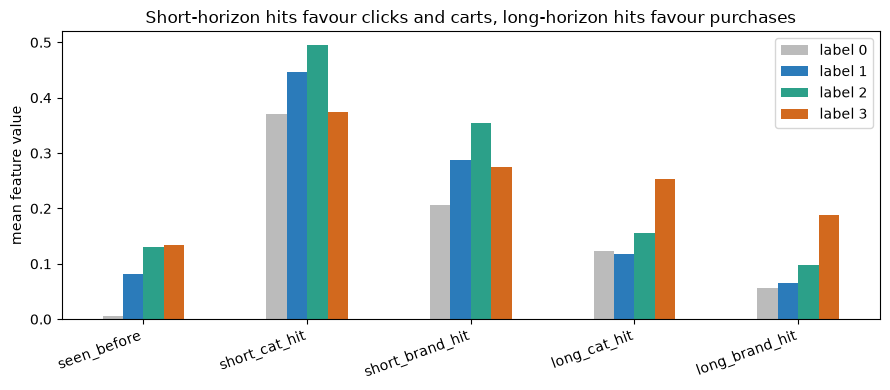

In [13]:
means = pd.DataFrame(summary["means_by_label"]).loc[summary["numeric_features"]]
means.columns = [f"label {c}" for c in means.columns]
display(means.round(3))

hit = ["seen_before", "short_cat_hit", "short_brand_hit", "long_cat_hit", "long_brand_hit"]
fig, ax = plt.subplots(figsize=(9, 4))
means.loc[hit].plot(kind="bar", ax=ax, color=["#bbbbbb", "#2b7bba", "#2ca089", "#d2691e"])
ax.set(ylabel="mean feature value", title="Short-horizon hits favour clicks and carts, long-horizon hits favour purchases")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Summary

* 26 features in six groups, built from complete histories with a **short** and a **long** horizon.
* Popularity priors use training histories only; labels never enter a feature.
* The dictionary in this notebook is checked against `feature_summary.json` (B.1).
* Recent intent (short horizon) tracks clicks and carts, lasting preference (orders) tracks purchases (B.2).

**Hand-off to Step 4 and Step 5:** `features.parquet` (plus `history.parquet` and `meta_subset.parquet`
for the neural sequences).

## Key results (highlighted)

Boxed summary of this step's main numbers, read from the run dir (falls back to `artifacts/corrected`).

In [14]:
import os, json
from pathlib import Path
import pandas as pd
_RUN = Path(os.environ.get("JD_RUN_DIR", PROJECT_ROOT / "artifacts" / "corrected"))
_BASES = [_RUN, PROJECT_ROOT / "artifacts" / "corrected",
          PROJECT_ROOT / "artifacts" / "step7_corrected",
          PROJECT_ROOT / "artifacts" / "diagnostics"]
def _find(name):
    for b in _BASES:
        p = b / name
        if p.exists():
            return p
    return None
def _json(name):
    p = _find(name); return json.loads(p.read_text()) if p else None
def _text(name):
    p = _find(name); return p.read_text() if p else None
def _csv(name):
    p = _find(name); return pd.read_csv(p) if p else None
def _box(title, lines):
    w = max([len(title)] + [len(x) for x in lines] + [46])
    print("=" * w); print(title); print("-" * w)
    for x in lines:
        print(x)
    print("=" * w)
fs = _json("feature_summary.json")
if fs:
    nf = fs.get("numeric_features", [])
    _box("STEP 3 - engineered features", [
        "rows            : %d" % fs.get("rows", 0),
        "numeric features: %d" % len(nf),
        "feature groups  : content, popularity, short/long horizon, affinity, re-engagement, activity",
    ])
else:
    _box("STEP 3", ["(feature_summary.json not found)"])

STEP 3 - engineered features
--------------------------------------------------------------------------------------------
rows            : 1781978
numeric features: 26
feature groups  : content, popularity, short/long horizon, affinity, re-engagement, activity
